# Introduction to Seaborn: Count Plot and Bar Plot

**Learning objectives**

By the end of this notebook, you will be able to:
- Explain what Seaborn is and why it is useful.
- Create a **count plot** to count records in each category.
- Create a **bar plot** to compare a numerical value across categories.
- Customize plots using titles, labels, colors, and other common parameters.
- Answer simple data-analysis questions using visualizations.

> **How to use this notebook:** Read each Markdown cell first, run the code cell below it, and observe the output. The code includes comments to explain each step.

## 1. What is Seaborn?

**Seaborn** is a Python data-visualization library built on top of Matplotlib. It helps us create attractive statistical graphs with relatively little code. It works especially well with data stored in a Pandas DataFrame.

### Why do we use Seaborn?
- To understand patterns and relationships in data.
- To compare categories.
- To summarize distributions.
- To make charts with useful default styles.

### Common Seaborn functions

| Function | What it is used for |
|---|---|
| `sns.countplot()` | Counts how many rows belong to each category |
| `sns.barplot()` | Shows a summary statistic (by default, the mean) for each category |
| `sns.histplot()` | Shows the distribution of numerical data |
| `sns.boxplot()` | Summarizes spread and highlights potential outliers |
| `sns.scatterplot()` | Shows the relationship between two numerical variables |
| `sns.lineplot()` | Shows trends, often over time |
| `sns.heatmap()` | Displays values using color, often for a correlation matrix |

### Install Seaborn if it is not already installed

Run this cell only if Seaborn is missing from your environment.

In [ ]:
# Install Seaborn from inside Jupyter if needed.
# Remove the # at the beginning only if installation is required.
# %pip install seaborn pandas matplotlib

### Import the libraries

- `pandas` helps us create and work with tabular data.
- `seaborn` creates the charts.
- `matplotlib.pyplot` helps us control the figure size and display plots.

In [1]:
import pandas as pd  # Work with data in table format
import seaborn as sns  # Create statistical visualizations
import matplotlib.pyplot as plt  # Control and display chart figures

sns.set_theme(style="whitegrid")  # Apply a clean chart style

## 2. Create a sample dataset

**Use case:** A training coordinator wants to understand student participation and performance across different academic branches.

We will use a small sample dataset with:
- `Student`: student identifier
- `Branch`: student's academic branch
- `Study_Hours`: hours studied per day
- `Marks`: marks scored out of 100

The data is created directly in the notebook, so no external file is required.

In [2]:
# Create a sample DataFrame containing student details
df = pd.DataFrame({
    "Student": ["S01", "S02", "S03", "S04", "S05", "S06",
                "S07", "S08", "S09", "S10", "S11", "S12"],
    "Branch": ["CSE", "ECE", "CSE", "ME", "ECE", "CSE",
               "CE", "ME", "ECE", "CSE", "CE", "ECE"],
    "Study_Hours": [3, 2, 5, 2, 4, 6, 3, 4, 5, 2, 6, 3],
    "Marks": [65, 58, 82, 55, 72, 91, 68, 70, 80, 60, 88, 75]
})

display(df)  # Display the complete dataset

,Student,Branch,Study_Hours,Marks
0,S01,CSE,3,65
1,S02,ECE,2,58
2,S03,CSE,5,82
3,S04,ME,2,55
4,S05,ECE,4,72
5,S06,CSE,6,91
6,S07,CE,3,68
7,S08,ME,4,70
8,S09,ECE,5,80
9,S10,CSE,2,60


## 3. Count Plot

### What is a count plot?

A **count plot** counts the number of observations in each category and displays those counts as bars.

For example, we can use a count plot to answer:
- How many students belong to CSE?
- How many students belong to ECE?
- Which branch has the most students in this dataset?

**Important difference:** A count plot counts rows. It does not calculate the average marks or sum of marks.

### Common `sns.countplot()` parameters

| Parameter | Meaning |
|---|---|
| `data` | The DataFrame containing the data |
| `x` | The categorical column displayed on the horizontal axis |
| `y` | Alternatively, a categorical column can be placed on the vertical axis |
| `hue` | Adds a second category to split each bar by color |
| `order` | Specifies the order of categories |
| `palette` | Specifies the color palette |
| `stat` | Controls what the bar height represents; commonly `"count"` or `"percent"` |
| `ax` | Draws the plot on a particular Matplotlib axes |

In recent Seaborn versions, `sns.countplot()` uses `data`, `x`, and optional parameters such as `hue`, `order`, and `palette`. The exact available options can depend on the installed Seaborn version.

### Activity 1: Count students in each branch

**Question:** How many students are there in each branch? Which branch has the highest number of students?

Before running the solution, try to predict which branch will have the tallest bar.

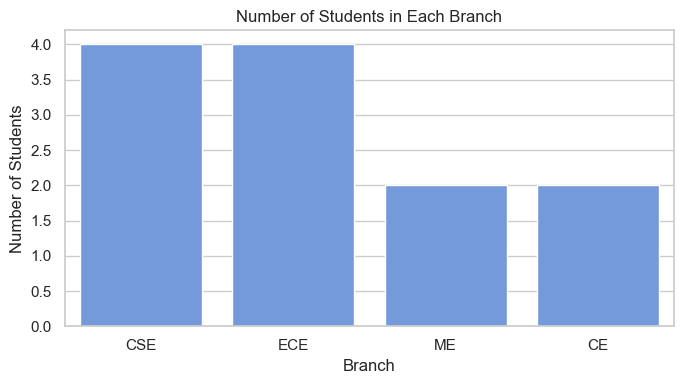

In [3]:
plt.figure(figsize=(7, 4))  # Set the width and height of the figure

sns.countplot(
    data=df,  # Use our student DataFrame
    x="Branch",  # Count the occurrences of each branch
    order=["CSE", "ECE", "ME", "CE"],  # Set a specific category order
    color="cornflowerblue"  # Use one color for all bars
)

plt.title("Number of Students in Each Branch")  # Add a chart title
plt.xlabel("Branch")  # Label the horizontal axis
plt.ylabel("Number of Students")  # Label the vertical axis
plt.tight_layout()  # Adjust spacing so labels fit neatly
plt.show()  # Display the chart

### Explanation of the solution

- `plt.figure(figsize=(7, 4))` creates a figure that is 7 inches wide and 4 inches tall.
- `sns.countplot(...)` counts how many rows have each branch value.
- `data=df` tells Seaborn which DataFrame to use.
- `x="Branch"` places the branch categories on the horizontal axis.
- `order=[...]` controls the order in which categories appear. It does not change the data.
- `color="cornflowerblue"` applies one color to all bars.
- `plt.title()`, `plt.xlabel()`, and `plt.ylabel()` add the title and axis labels.
- `plt.tight_layout()` helps prevent labels from being clipped.
- `plt.show()` displays the chart.

**Expected interpretation:** CSE and ECE each have 4 students, while ME and CE each have 2 students. CSE and ECE therefore tie for the highest count.

### Activity 2: Count students by branch and study-hours group

**Question:** How many students in each branch study for 3 hours or less versus more than 3 hours?

We will first create a new categorical column called `Study_Group`, then use `hue` to split each branch's bars by study group.

,Student,Branch,Study_Hours,Study_Group
0,S01,CSE,3,3 hours or less
1,S02,ECE,2,3 hours or less
2,S03,CSE,5,More than 3 hours
3,S04,ME,2,3 hours or less
4,S05,ECE,4,More than 3 hours
5,S06,CSE,6,More than 3 hours
6,S07,CE,3,3 hours or less
7,S08,ME,4,More than 3 hours
8,S09,ECE,5,More than 3 hours
9,S10,CSE,2,3 hours or less


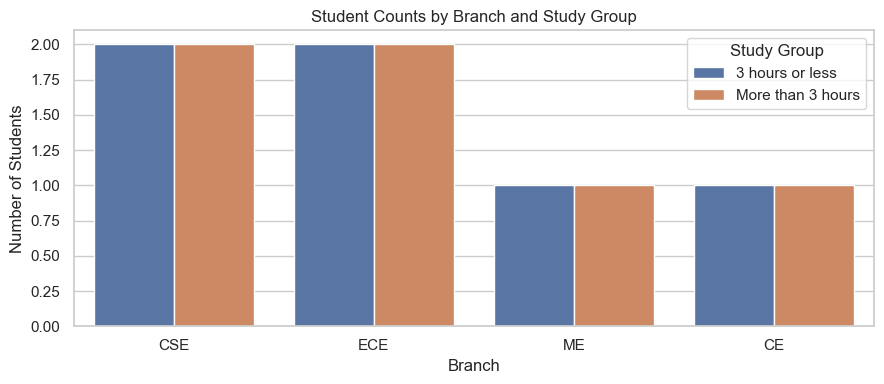

In [4]:
# Create a category based on the number of study hours
df["Study_Group"] = df["Study_Hours"].apply(
    lambda hours: "3 hours or less" if hours <= 3 else "More than 3 hours"
)
display(df[["Student", "Branch", "Study_Hours", "Study_Group"]])  # Inspect the new column
plt.figure(figsize=(9, 4))  # Create a wider figure for the grouped bars
sns.countplot(
    data=df,  # Use the student DataFrame
    x="Branch",  # Group students by branch
    hue="Study_Group",  # Split each branch by study group
    order=["CSE", "ECE", "ME", "CE"]  # Keep branch order consistent
)
plt.title("Student Counts by Branch and Study Group")  # Add title
plt.xlabel("Branch")  # Label x-axis
plt.ylabel("Number of Students")  # Label y-axis
plt.legend(title="Study Group")  # Give the legend a meaningful title
plt.tight_layout()  # Improve spacing
plt.show()  # Display the chart

### What does `hue` do?

`hue="Study_Group"` adds another categorical dimension to the chart. Each branch now has separate colored bars for the two study groups.

Use `hue` when you want to compare subgroups within each category. For example, it can compare students by branch and study group, or sales by region and product type.

## 4. Bar Plot

### What is a bar plot?

A **bar plot** compares a numerical measurement across categories. By default, `sns.barplot()` calculates the **mean** of the numerical variable for each category.

For example, we can compare the **average marks** of students in CSE, ECE, ME, and CE.

**Key difference:**
- **Count plot:** counts how many records are in each category.
- **Bar plot:** summarizes a numerical column for each category (by default, the mean).

A bar plot is useful when the question asks about average marks, average salary, average sales, or another numerical measure by category.

### Common `sns.barplot()` parameters

| Parameter | Meaning |
|---|---|
| `data` | The DataFrame containing the data |
| `x` | Categories to display on the horizontal axis |
| `y` | Numerical values to summarize |
| `hue` | Splits each category into subgroups |
| `order` | Controls the category order |
| `estimator` | Function used to summarize values; default is the mean |
| `errorbar` | Controls uncertainty intervals; recent versions commonly use `"ci"`, `"sd"`, or `None` |
| `palette` | Selects colors for categories |
| `ax` | Draws the chart on a specified Matplotlib axes |

By default, Seaborn's bar plot typically displays a confidence interval around the estimated mean. In the first example below, `errorbar=None` hides the interval so the mean bars are easier to read. This parameter is for recent Seaborn versions; older versions may use `ci=None`.

### Activity 3: Compare average marks by branch

**Question:** Which branch has the highest average marks?

Use `sns.barplot()` with `Branch` on the x-axis and `Marks` on the y-axis.

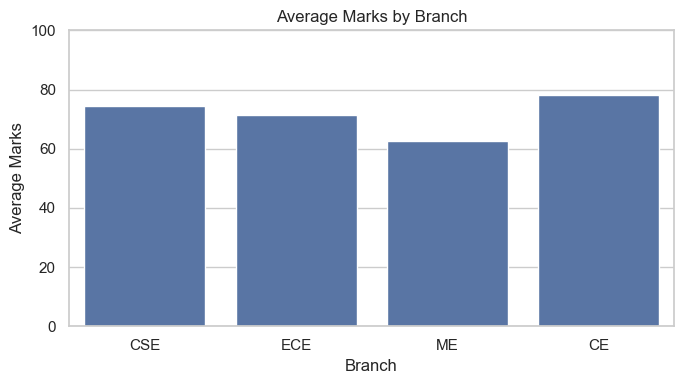

In [5]:
plt.figure(figsize=(7, 4))  # Set the figure size
sns.barplot(
    data=df,  # Use the student DataFrame
    x="Branch",  # Compare categories by branch
    y="Marks",  # Summarize the numerical marks column
    order=["CSE", "ECE", "ME", "CE"],  # Set the order of branches
    errorbar=None  # Hide uncertainty intervals for this simple comparison
)
plt.title("Average Marks by Branch")  # Add a descriptive title
plt.xlabel("Branch")  # Label the horizontal axis
plt.ylabel("Average Marks")  # Label the vertical axis
plt.ylim(0, 100)  # Set the marks axis from 0 to 100
plt.tight_layout()  # Adjust chart spacing
plt.show()  # Display the chart

### Explanation of the solution

- `x="Branch"` creates one bar for each branch.
- `y="Marks"` tells Seaborn which numerical values to summarize.
- The default estimator is the mean, so each bar represents that branch's average marks.
- `errorbar=None` hides the uncertainty interval in this example. It does **not** change the average itself.
- `plt.ylim(0, 100)` sets a sensible scale for marks out of 100.

**Expected interpretation:** Compare the heights of the bars to identify the branch with the highest average marks. The tallest bar represents the highest mean, not the highest individual mark.

### Verify the bar plot using Pandas

A plot helps us see a pattern, but we can also calculate the exact averages with Pandas.

In [ ]:
branch_average = df.groupby("Branch")["Marks"].mean().sort_values(ascending=False)  # Calculate and rank mean marks
display(branch_average)  # Display exact average marks for each branch

### Activity 4: Change the summary statistic

**Question:** Instead of average marks, what if the training coordinator wants to compare the **maximum mark** in each branch?

Use `estimator=max`. The chart will now show the highest individual mark for each branch rather than the average.

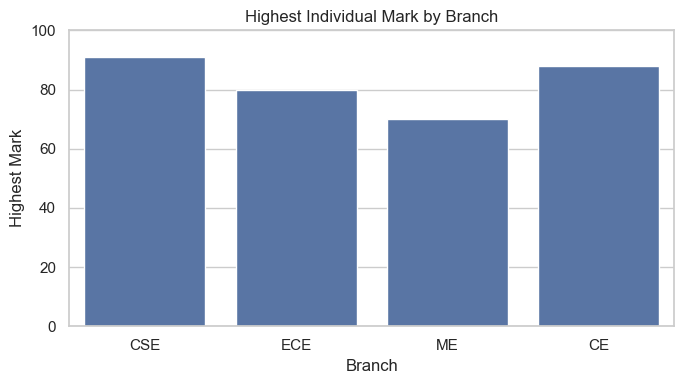

In [6]:
plt.figure(figsize=(7, 4))  # Create a new figure

sns.barplot(
    data=df,  # Use the same student DataFrame
    x="Branch",  # Display each branch as a category
    y="Marks",  # Use marks as the numerical measurement
    estimator=max,  # Show the maximum mark in each branch
    errorbar=None,  # Hide uncertainty intervals for this summary
    order=["CSE", "ECE", "ME", "CE"]  # Keep category order consistent
)

plt.title("Highest Individual Mark by Branch")  # Add title
plt.xlabel("Branch")  # Label x-axis
plt.ylabel("Highest Mark")  # Label y-axis
plt.ylim(0, 100)  # Use the marks scale
plt.tight_layout()  # Improve spacing
plt.show()  # Display the chart

### Why is `estimator` useful?

`estimator` decides how the numerical values in each category are summarized.

- Default (`estimator=np.mean`): average value.
- `estimator=max`: largest value.
- `estimator=min`: smallest value.
- `estimator=sum`: total value.

For example, a business analyst might use the mean to compare average sales per store, or the sum to compare total sales per region. If you use `sum`, remember that the result is a total—not an average.

## 5. Practice Questions

Try to solve these questions before looking at the solutions. You can create a new code cell below each question.

### Question 1 — Count plot
Create a count plot showing the number of students in each branch. Add a title and axis labels.

### Question 2 — Count plot with `hue`
Create a count plot showing the number of students in each branch, split by `Study_Group`.

### Question 3 — Bar plot
Create a bar plot showing the average `Study_Hours` for each branch.

### Question 4 — Bar plot with a different estimator
Create a bar plot showing the maximum `Marks` for each branch.

### Question 5 — Interpret the charts
In your own words, explain the difference between a count plot and a bar plot. Give one example of when you would use each.

## 6. Practice Solutions

### Solution 1 — Count students by branch

In [ ]:
plt.figure(figsize=(7, 4))  # Set figure size
sns.countplot(data=df, x="Branch")  # Count students in each branch
plt.title("Student Count by Branch")  # Add title
plt.xlabel("Branch")  # Add x-axis label
plt.ylabel("Student Count")  # Add y-axis label
plt.tight_layout()  # Adjust spacing
plt.show()  # Display plot

### Solution 2 — Count plot split by study group

In [ ]:
plt.figure(figsize=(9, 4))  # Set figure size
sns.countplot(data=df, x="Branch", hue="Study_Group")  # Count by branch and study group
plt.title("Student Count by Branch and Study Group")  # Add title
plt.xlabel("Branch")  # Add x-axis label
plt.ylabel("Student Count")  # Add y-axis label
plt.legend(title="Study Group")  # Label the colors
plt.tight_layout()  # Adjust spacing
plt.show()  # Display plot

### Solution 3 — Average study hours by branch

In [ ]:
plt.figure(figsize=(7, 4))  # Set figure size
sns.barplot(data=df, x="Branch", y="Study_Hours", errorbar=None)  # Show mean study hours
plt.title("Average Study Hours by Branch")  # Add title
plt.xlabel("Branch")  # Add x-axis label
plt.ylabel("Average Study Hours")  # Add y-axis label
plt.tight_layout()  # Adjust spacing
plt.show()  # Display plot

### Solution 4 — Maximum marks by branch

In [ ]:
plt.figure(figsize=(7, 4))  # Set figure size
sns.barplot(data=df, x="Branch", y="Marks", estimator=max, errorbar=None)  # Show maximum marks
plt.title("Maximum Marks by Branch")  # Add title
plt.xlabel("Branch")  # Add x-axis label
plt.ylabel("Maximum Marks")  # Add y-axis label
plt.ylim(0, 100)  # Set the marks scale
plt.tight_layout()  # Adjust spacing
plt.show()  # Display plot

### Solution 5 — Sample answer

A **count plot** counts how many records are present in each category. For example, it can show how many students belong to each branch.

A **bar plot** summarizes a numerical variable for each category. By default, it shows the mean. For example, it can compare average marks across branches.

**Remember:** A count plot answers “How many?” A bar plot often answers “What is the average (or another summary) for each group?”

## 7. Quick Reference

```python
# Count observations in each category
sns.countplot(data=df, x="Branch")

# Count observations by category and subgroup
sns.countplot(data=df, x="Branch", hue="Study_Group")

# Compare average numerical values by category (default estimator is mean)
sns.barplot(data=df, x="Branch", y="Marks", errorbar=None)

# Compare maximum numerical values by category
sns.barplot(data=df, x="Branch", y="Marks", estimator=max, errorbar=None)
```

### Final takeaway
- Choose **`countplot()`** when you want to count category occurrences.
- Choose **`barplot()`** when you want to compare a numerical summary across categories.
- Add clear titles and axis labels so that the chart communicates its purpose.